# 5. Massive black hole binaries: LISA and a detector network

**Goal:** initialise a detector network, inject one source, and compare
LISA with **LISA + Taiji + TianQin**.

Zero-noise injection. Only ecliptic longitude $\lambda$ and latitude $\beta$ vary, and they vary over
the **whole sky** under an isotropic prior; the other nine source parameters stay
fixed. This is therefore a two-parameter conditional sky posterior, not a fully
marginalised one. 

In [1]:
%matplotlib inline
# Paths and plotting defaults only; the scientific workflow is below.
from tutorial_tools.common import DATA, OUTPUT, ORBIT, DAY, load_arrays, inner
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Parallel sampling, as in the Triangle-BBH network example: the "fork" start
# method lets the notebook-defined likelihood class reach the worker processes.
import multiprocessing
if multiprocessing.get_start_method(allow_none=True) != "fork":
    multiprocessing.set_start_method("fork", force=True)
NPROC = multiprocessing.cpu_count()
print("CPU cores:", NPROC, "| start method:", multiprocessing.get_start_method())


CPU cores: 12 | start method: fork


## 1. Initialise the detector orbits and noise models

In [2]:
from Triangle.Constants import YEAR
from Triangle.Orbit import HeliocentricEqualArmAnalyticOrbit, GeocentricEqualArmAnalyticOrbit
from Triangle.Noise import TDIPSDs

missions = ["LISA", "Taiji", "TianQin"]
orbits = [
    HeliocentricEqualArmAnalyticOrbit(L=2.5e9, kap=-np.deg2rad(40), lam=0.12801155,
                                    dt=DAY, Tobs=2*YEAR, pn_order=0),
    HeliocentricEqualArmAnalyticOrbit(L=3e9, kap=0., lam=6.10414095,
                                    dt=DAY, Tobs=2*YEAR, pn_order=0),
    GeocentricEqualArmAnalyticOrbit(L=np.sqrt(3)*1e8, kappa0=1.22975531,
                                   kappa_earth=-np.deg2rad(20), dt=6000.,
                                   Tobs=2*YEAR, pn_order=0)]
noise_models = [TDIPSDs(L=2.5e9, sacc=3e-15, sro=15e-12),
                TDIPSDs(L=3e9, sacc=3e-15, sro=8e-12),
                TDIPSDs(L=np.sqrt(3)*1e8, sacc=1e-15, sro=1e-12)]

PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


No pyseobnr.
no cupy 


## 2. Initialise the waveform and TDI response

In [3]:
from Triangle_BBH.Waveform import WaveformGeneratorFRef
from Triangle_BBH.Response import FDTDIResponseGeneratorFRefNetwork

T = 5*DAY
f = np.arange(int(np.ceil(1e-4*T)), int(0.015*T)+1)/T
waveform_generator = WaveformGeneratorFRef(mode="full")
generator = FDTDIResponseGeneratorFRefNetwork(
    orbit_classes=orbits, waveform_generator=waveform_generator)
generator_lisa = FDTDIResponseGeneratorFRefNetwork(
    orbit_classes=orbits[:1], waveform_generator=waveform_generator)
p = dict(chirp_mass=1e6, mass_ratio=0.4, spin_1z=0.3, spin_2z=-0.1,
         reference_time=30., reference_phase=0.8, luminosity_distance=18000.,
         inclination=1.1, longitude=3., latitude=-0.6, psi=0.4)
MODES = [(2, 2), (3, 3), (4, 4), (2, 1), (3, 2), (4, 3)]
options = dict(fmin=float(f[0]), fmax=float(f[-1]), fref=1e-3, modes=MODES,
               tmin=28., tmax=33., tref_at_constellation=False,
               TDIGeneration="2nd", optimal_combination=True, drop_T=True,
               interpolation_method=None)

# Move the reference frequency to this source's merger frequency, as the
# repository network example does: quoted at 1 mHz, the phase of the higher
# modes would be extrapolated over too many cycles.
grids, amplitudes, phases, times = waveform_generator(
    parameters=p, Nfreqs=1024, fmin=options["fmin"], fmax=options["fmax"],
    fref=options["fref"], freqs=f)
options["fref"] = float(grids[0][int(np.argmax(amplitudes[(2, 2)][0]*grids[0]**2))])

def network_waveform(parameters):
    """Mode-summed network response, shape (6, Nfreq)."""
    h = np.asarray(generator.Response(parameters, f, **options))
    return h.sum(axis=1) if h.ndim == 3 else h


no cupy
No CuPy or GPU PhenomHM module.
has BBHx waveform


## 3. Make a zero-noise injection and check SNR

In [4]:
psd = np.array([model.PSD_A2(f) for model in noise_models for channel in ("A", "E")])
weight = 4/T/psd
h = network_waveform(p)
initial_snr = np.sqrt(np.sum(abs(h[:2])**2*weight[:2]))
p['luminosity_distance'] *= initial_snr/80
h = network_waveform(p)
data = h.copy()
sky0 = np.array([p["longitude"], p["latitude"]])
snrs = np.sqrt(np.sum((abs(h)**2*weight).reshape(3, 2, -1), axis=(1, 2)))
print("SNR per mission:", dict(zip(missions, snrs)))
print("Network SNR:", np.linalg.norm(snrs))
print("Injected (lambda, beta) [rad]:", sky0)
np.testing.assert_allclose(snrs[0], 80, rtol=1e-10)
assert np.array_equal(data, h)


SNR per mission: {'LISA': 80.00000000000001, 'Taiji': 126.64060731449497, 'TianQin': 42.366757507988396}
Network SNR: 155.66883298439933
Injected (lambda, beta) [rad]: [ 3.  -0.6]


## 4. Build the heterodyne likelihood

In [5]:
from Triangle_BBH.Utils import NetworkHMLikelihood, ParamDict2ParamArrFref

# C(f) = S(f)/(4 df) with df = 1/T; the detectors are independent, so the
# network covariance is diagonal and C^-1 = 4/T/S is the weight used above.
likelihoods = {}
for label, generator_kind, channels in (("lisa", generator_lisa, 2),
                                        ("network", generator, 6)):
    cov_inv = np.zeros((len(f), channels, channels), dtype=complex)
    index = np.arange(channels)
    cov_inv[:, index, index] = weight[:channels].T
    like = NetworkHMLikelihood(response_generator=generator_kind, frequency=f,
                               data=data[:channels],
                               inverse_covariance_matrix=cov_inv,
                               response_kwargs=options, Fref_waveform=True)
    like.prepare_het_log_like(base_parameters=p, num_het_frequency=256)
    likelihoods[label] = like
    print(f"{label:7s}: {like.Nmodes} modes, {like.Nchannels} channels, "
          f"{like.Nfreqs_dense} dense bins, {len(like.het_frequency)} "
          "heterodyne points")

# The approximation is local, so check it before sampling: differences of the
# heterodyned log-likelihood must match differences of the full one.
print("\nselection, displacement [rad]      full - full(0)     het - het(0)"
      "      difference")
for label, like in likelihoods.items():
    at = ParamDict2ParamArrFref(p)
    full0, het0 = like.full_log_like(at), like.het_log_like(at)
    for dlon, dlat in ((0.002, 0.002), (0.01, 0.0), (0.0, 0.01)):
        moved = ParamDict2ParamArrFref({**p, "longitude": sky0[0]+dlon,
                                        "latitude": sky0[1]+dlat})
        full = like.full_log_like(moved)-full0
        het = like.het_log_like(moved)-het0
        print(f"  {label:7s} ({dlon:+.3f}, {dlat:+.3f})  {full:+.6e}  "
              f"{het:+.6e}  {het-full:+.2e}")
        np.testing.assert_allclose(het, full, rtol=1e-4, atol=1e-6)


lisa   : 6 modes, 2 channels, 6354 dense bins, 256 heterodyne points
network: 6 modes, 6 channels, 6354 dense bins, 256 heterodyne points

selection, displacement [rad]      full - full(0)     het - het(0)      difference
  lisa    (+0.002, +0.002)  -7.410558e-01  -7.410519e-01  +3.92e-06
  lisa    (+0.010, +0.000)  -2.789565e-01  -2.789530e-01  +3.51e-06
  lisa    (+0.000, +0.010)  -2.161566e+01  -2.161562e+01  +3.50e-05
  network (+0.002, +0.002)  -8.101667e+00  -8.101630e+00  +3.73e-05
  network (+0.010, +0.000)  -4.967422e+01  -4.967415e+01  +6.91e-05
  network (+0.000, +0.010)  -6.671626e+01  -6.671610e+01  +1.60e-04


## 5. Full-sky prior, and the sampler
Nothing is localised by hand here: the prior is the isotropic sky prior of
notebook 03 and of the repository's network example, applied to the whole
sphere, $p(\lambda,\beta)\propto\cos\beta$ over $\lambda\in[0,2\pi)$ and
$\beta\in[-\pi/2,\pi/2]$. No Fisher matrix is computed or used, so the sampled
region is not tailored to the injection — a second solution, if these data admit
one, stays in the posterior instead of being cut away.

Sampling follows the repository example: `bilby.run_sampler(sampler="nessai",
nlive=1000, stopping=0.1, n_pool=cpu_count())` once per detector selection, with
the same seed for both runs. With heterodyning a likelihood call costs about
$8$ ms for LISA and $21$ ms for the network, against $45$ ms and $99$ ms for the
full likelihood with the same six modes; the worker pool then does the initial
population in parallel.


### Set the sky priors explicitly
Two parameters are sampled and nine are held at their injected values, so the
prior alone defines the search region. It is the full sky, in the same forms as
notebook 03.

| parameter | prior | range |
|---|---|---|
| $\lambda$ | bilby `Uniform`, `boundary="periodic"` | $[0,\,2\pi)$ |
| $\beta$ | bilby `Cosine` | $[-\pi/2,\,\pi/2]$, $p\propto\cos\beta$ |



In [6]:
import bilby

# Full-sky prior: isotropic on the sphere, uniform and periodic in longitude.
sky_priors = bilby.core.prior.PriorDict()
sky_priors["longitude"] = bilby.prior.Uniform(0., 2*np.pi, name="longitude",
                                              boundary="periodic")
sky_priors["latitude"] = bilby.prior.Cosine(-np.pi/2., np.pi/2.,
                                            name="latitude")
print(sky_priors)

class SkyLikelihood(bilby.Likelihood):
    """bilby wrapper: only longitude and latitude vary; the other nine
    parameters stay at their injected values inside the dictionary p."""
    def __init__(self, network_likelihood):
        super().__init__(parameters={"longitude": None, "latitude": None})
        self.network_likelihood = network_likelihood

    def log_likelihood(self):
        parameters = dict(p, longitude=self.parameters["longitude"],
                          latitude=self.parameters["latitude"])
        return float(self.network_likelihood.het_log_like(
            ParamDict2ParamArrFref(parameters)))

for label, like in likelihoods.items():
    wrapper = SkyLikelihood(like)
    wrapper.parameters.update(dict(zip(("longitude", "latitude"), sky0)))
    print(label, "channels: log L at injection =", wrapper.log_likelihood())


{'longitude': Uniform(minimum=0.0, maximum=6.283185307179586, name='longitude', latex_label='longitude', unit=None, boundary='periodic'), 'latitude': Cosine(minimum=-1.5707963267948966, maximum=1.5707963267948966, name='latitude', latex_label='latitude', unit=None, boundary=None)}
lisa channels: log L at injection = 3199.973183496865
network channels: log L at injection = 12116.330383990458


## 6. Sample the sky posterior with nessai



In [7]:
import time

results, draws = {}, {}
start_clock = time.perf_counter()
for label, like in likelihoods.items():
    run_start = time.perf_counter()
    results[label] = bilby.run_sampler(
        likelihood=SkyLikelihood(like), priors=sky_priors, sampler="nessai",
        nlive=1000, stopping=0.1, n_pool=NPROC, pytorch_threads=1,
        seed=20261121, outdir=str(OUTPUT/"mbhb_network_nessai"), label=label,
        resume=False, plot=False,
        # The native response is reproducible only to ~1e-16 relative (the
        # internal summation order changes between calls), so nestai's
        # "same parameters, same value" check would trip. The repository
        # network example passes this flag for the same reason.
        allow_multi_valued_likelihood=True)
    draws[label] = results[label].posterior[["longitude", "latitude"]].to_numpy()
    mean, sigma = draws[label].mean(axis=0), draws[label].std(axis=0)
    print(f"{label:7s}: {len(draws[label])} draws in "
          f"{time.perf_counter()-run_start:.0f} s | mean = "
          f"({mean[0]:.5f}, {mean[1]:.5f}) rad | 1 sigma = "
          f"({sigma[0]:.2e}, {sigma[1]:.2e}) rad", flush=True)
print("Total sampling time [s]:", round(time.perf_counter()-start_clock, 1))


15:33 bilby INFO    : Running for label 'lisa', output will be saved to '/Users/taijidatacenter/Desktop/PTASchool/Du_Minghui_Lecture/student_tutorials/outputs/mbhb_network_nessai'
/Users/taijidatacenter/miniconda3/envs/tri_env/lib/python3.9/site-packages/bilby/core/utils/log.py:73: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  vdict[key] = str(getattr(sys.modules[key], "__version__", "N/A"))
15:33 bilby INFO    : Analysis priors:
15:33 bilby INFO    : longitude=Uniform(minimum=0.0, maximum=6.283185307179586, name='longitude', latex_label='longitude', unit=None, boundary='periodic')
15:33 bilby INFO    : latitude=Cosine(minimum=-1.5707963267948966, maximum=1.5707963267948966, name='latitude', latex_label='latitude', unit=None, boundary=None)
15:33 bilby INFO    : Analysis likelihood class: <class '__main__.SkyLikelihood'>
15:33 bilby INFO    : Analysis likelih

lisa   : 2776 draws in 3 s | mean = (3.00052, -0.59967) rad | 1 sigma = (2.04e-02, 2.28e-03) rad


15:33 bilby INFO    : Running for label 'network', output will be saved to '/Users/taijidatacenter/Desktop/PTASchool/Du_Minghui_Lecture/student_tutorials/outputs/mbhb_network_nessai'
/Users/taijidatacenter/miniconda3/envs/tri_env/lib/python3.9/site-packages/bilby/core/utils/log.py:73: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  vdict[key] = str(getattr(sys.modules[key], "__version__", "N/A"))
15:33 bilby INFO    : Analysis priors:
15:33 bilby INFO    : longitude=Uniform(minimum=0.0, maximum=6.283185307179586, name='longitude', latex_label='longitude', unit=None, boundary='periodic')
15:33 bilby INFO    : latitude=Cosine(minimum=-1.5707963267948966, maximum=1.5707963267948966, name='latitude', latex_label='latitude', unit=None, boundary=None)
15:33 bilby INFO    : Analysis likelihood class: <class '__main__.SkyLikelihood'>
15:33 bilby INFO    : Analysis like

network: 2721 draws in 4 s | mean = (2.99998, -0.59998) rad | 1 sigma = (1.48e-03, 1.29e-03) rad
Total sampling time [s]: 7.0


## 7. Compare the sampled posteriors
Both runs are drawn with the same kernel-density renderer as notebooks 02 and 03,
in one corner, on two axes that need special care: $\lambda$ is periodic, so the
kernel wraps through the $0/2\pi$ seam instead of piling up against the edge, and
$\beta$ is bounded, so kernel mass that leaks past a pole is reflected back. The
filled 68% and 95% contours are highest-density regions, so the enclosed sample
mass is exact; the `+` and the thin lines mark the injection. The axes follow the
posterior, not the whole prior, so a mode far narrower than the sky is resolved.

The two selections differ in width by more than an order of magnitude, so the
panel is set by the LISA contour and the network one appears inside it as a thin
ellipse — that collapse *is* the result:

| selection | $\sigma_\lambda$ [rad] | $\sigma_\beta$ [rad] |
|---|---|---|
| LISA | $\approx 2.0\times10^{-2}$ | $\approx 2.2\times10^{-3}$ |
| LISA + Taiji + TianQin | $\approx 1.5\times10^{-3}$ | $\approx 1.3\times10^{-3}$ |

LISA alone is much better at $\beta$ than at $\lambda$: a single constellation
sees the ecliptic latitude well but leaves a long arc of longitudes at similar
likelihood, which shows up as the tilted, elongated blue contour. Adding the two
additional constellations breaks that arc and shrinks $\sigma_\lambda$ by a
factor of about fourteen, while $\beta$ improves by less than a factor of two —
a clear example of how a network helps with the direction that one detector
cannot pin down. Both modes stay centred on the injection.

A caveat about the higher modes: with nine parameters frozen, the sky widths
come out within a few per cent of what the $(2,2)$-only model gives. The sky is
set by the dominant mode; what the $(3,3)$, $(4,4)$, $(2,1)$, $(3,2)$ and
$(4,3)$ modes buy is a faithful waveform when inclination, masses and distance
are free (notebook 04), and heterodyning is what pays for them here.

The kernel width is the shared $0.30$ of the sample standard deviation, which is
appropriate while each posterior is a single compact mode; `bandwidth=` can be
lowered to expose how much of the smoothness comes from the kernel.


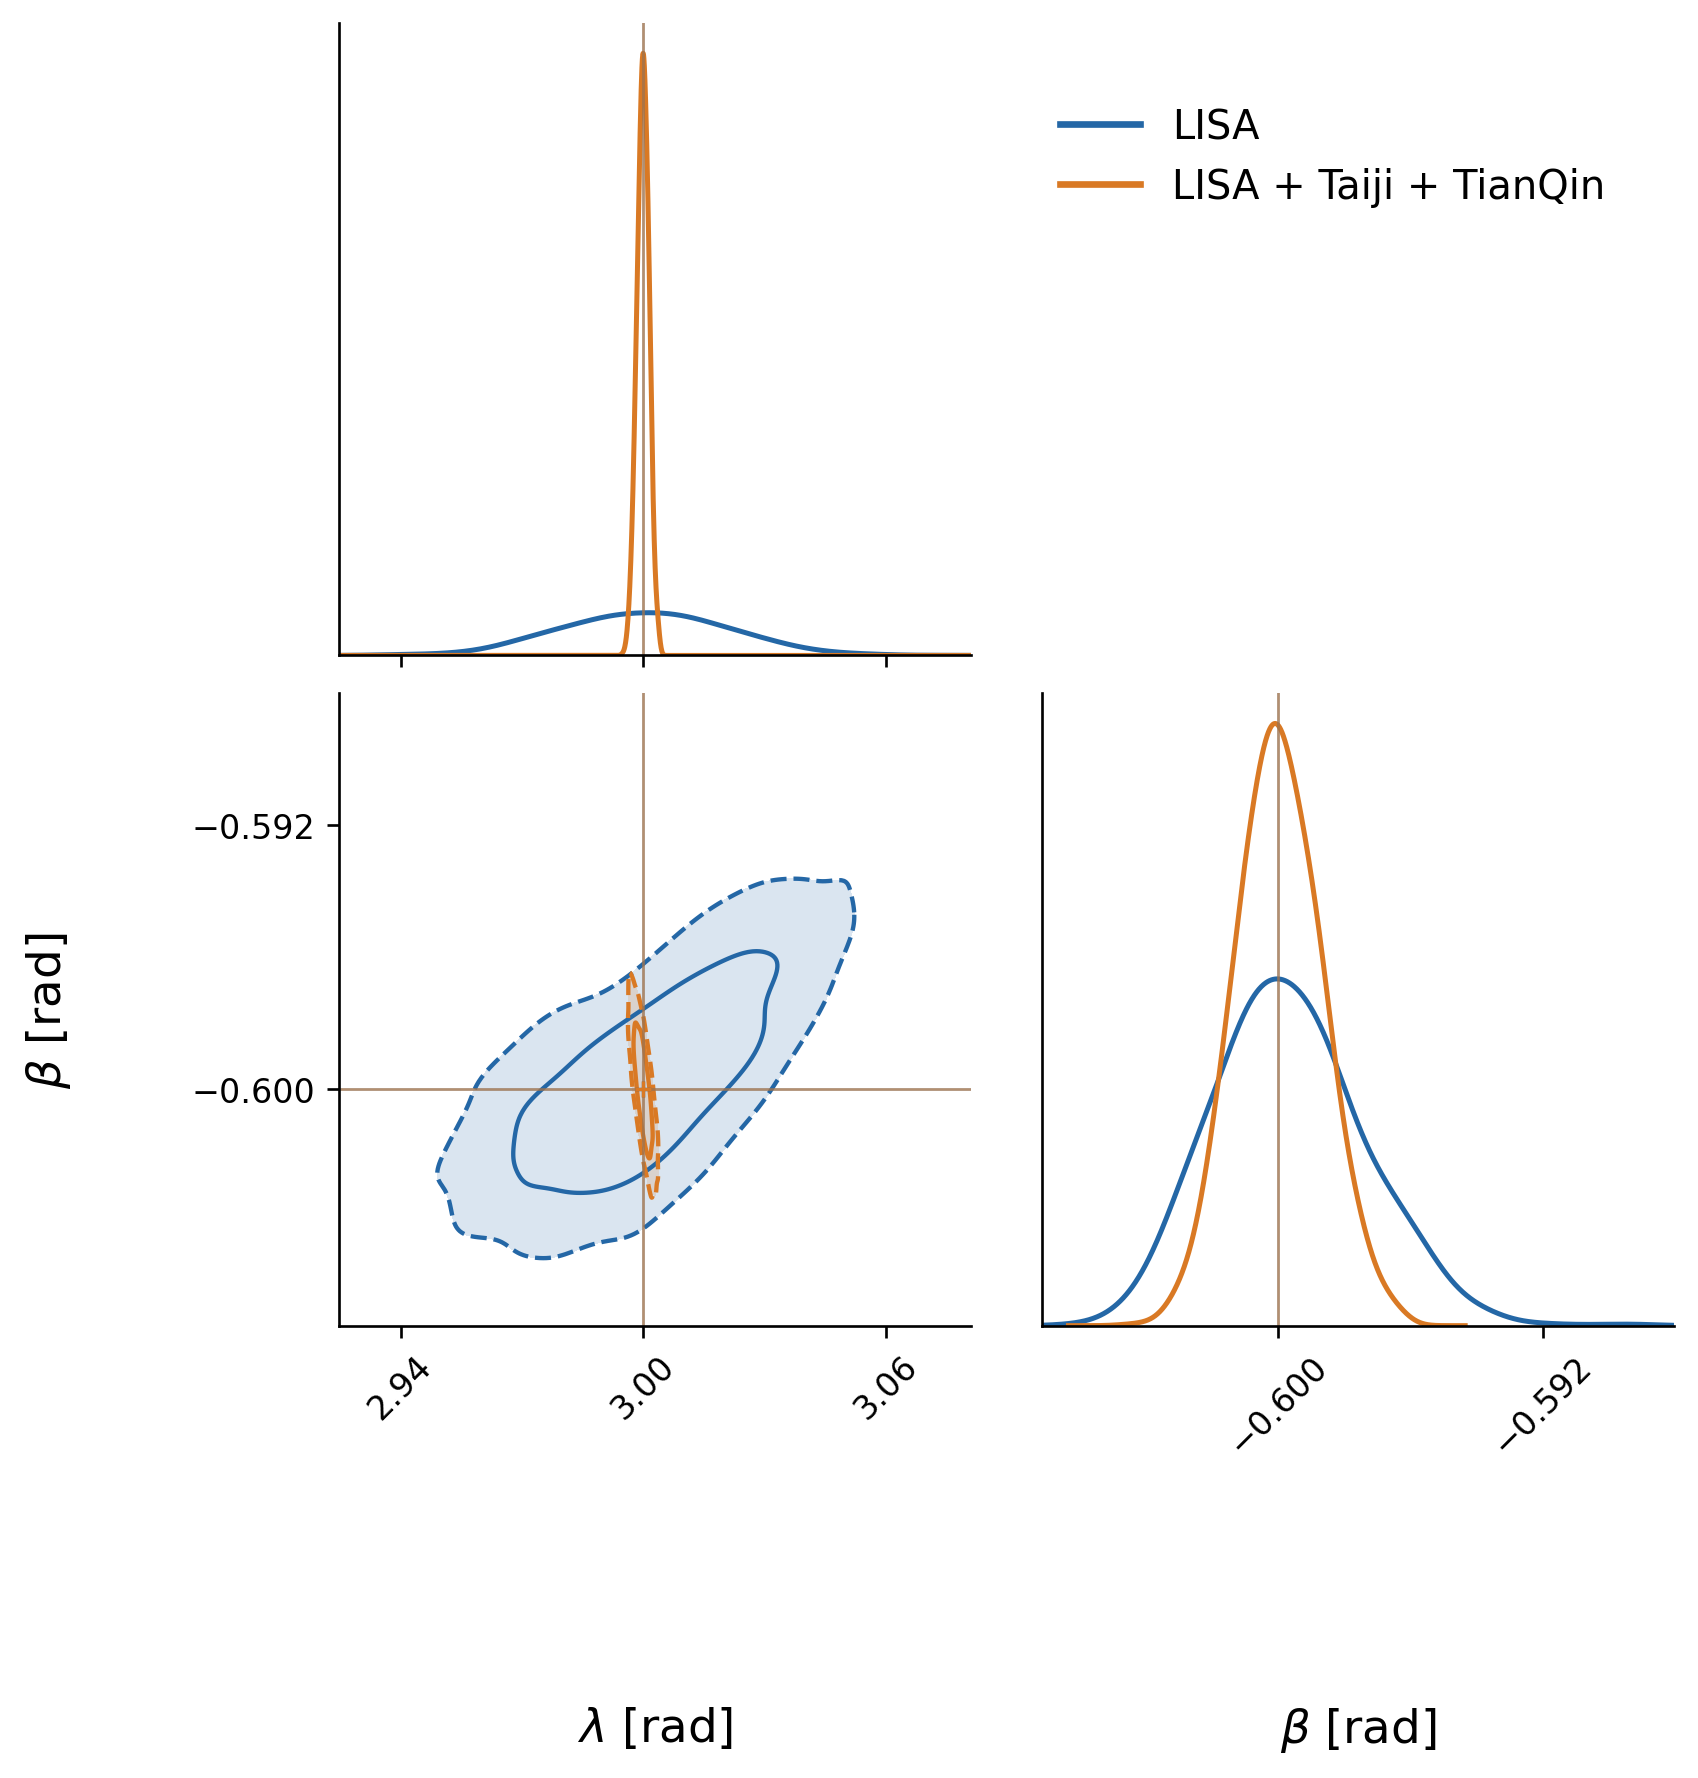

In [8]:
from tutorial_tools.corners import corner_plot

# The same kernel-density renderer as notebooks 02 and 03, with both selections
# in one corner. The LISA mode is much wider in longitude, so it sets the axes
# and the network mode sits inside it as a narrow ellipse.
corner_plot([draws["lisa"], draws["network"]],
            labels=[r"$\lambda$ [rad]", r"$\beta$ [rad]"],
            path=OUTPUT/"mbhb_network_posterior.png", truths=None,
            truth_sets=[sky0, sky0], colors=["#2467A6", "#D97924"],
            legend=["LISA", "LISA + Taiji + TianQin"],
            periods={0: 2*np.pi}, bounds={1: (-np.pi/2, np.pi/2)})
display(Image(filename=str(OUTPUT/"mbhb_network_posterior.png"), width=720))
np.savez_compressed(OUTPUT/"mbhb_network_sky_posterior.npz",
                    injection_frequency_Hz=f, injection_data=data, nominal_psd=psd,
                    injected_sky_rad=sky0,
                    lisa_draws=draws["lisa"], network_draws=draws["network"])
